# Nested Kriging (Gap-Missing): `electricity/H`

NaN gaps (sensor outages / calendar holes) are linearly imputed before windowing. The model is otherwise identical to the no-missing procedure: Layer 1 learns ℓ̃(x) via Gaussian MLE per block; Layer 2 runs nested kriging with the Gibbs kernel.

In [1]:
import os, sys
from pathlib import Path

def _find_repo_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "src").exists() and (candidate / "gift_eval").exists():
            return candidate
    raise RuntimeError("Could not locate KMD_TS repo root.")

REPO_ROOT = _find_repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.environ.setdefault("GIFT_EVAL", str(REPO_ROOT / "GiftEval_data"))
print("Repo root:", REPO_ROOT)

Repo root: /Users/jonghyeonlee/KMD_TS


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from gift_eval.data import Dataset
from src.nested_kriging import (
    LengthscaleField, NestedKrigingForecaster,
    fit_gibbs_lengthscale_field,
    pool_windows_from_series_with_missing,
)
# ── Auto-save figures to experiments/figures/ ───────────────────────────────
import matplotlib.pyplot as _nk_plt
if not getattr(_nk_plt.show, '_nk_patched', False):
    _nk_fig_dir = REPO_ROOT / "experiments" / "figures"
    _nk_fig_dir.mkdir(parents=True, exist_ok=True)
    _nk_fig_ctr = [0]
    _nk_max_figs = 4   # save at most 4 figures per notebook run
    _nk_show_orig = _nk_plt.show

    def _nk_show(*_a, **_kw):
        if _nk_fig_ctr[0] < _nk_max_figs:
            _safe = DATASET_NAME.replace("/", "__").replace(" ", "_")
            _p = _nk_fig_dir / f"{_safe}_fig{_nk_fig_ctr[0]:02d}.png"
            _nk_plt.savefig(str(_p), bbox_inches="tight", dpi=150)
            print(f"[fig saved → {_p}]")
        _nk_fig_ctr[0] += 1
        _nk_show_orig(*_a, **_kw)

    _nk_show._nk_patched = True
    _nk_plt.show = _nk_show


/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/gluonts/json.py:102: UserWarning: Using `json`-module for json-handling. Consider installing one of `orjson`, `ujson` to speed up serialization and deserialization.
  warnings.warn(


In [3]:
DATASET_NAME = "electricity/H"
TERM = "short"
TO_UNIVARIATE = False
SERIES_INDEX = 0

MAX_SERIES              = 200
MAX_WINDOWS_PER_SERIES  = 20
MIN_OBSERVED_FRACTION   = 0.5   # min fraction of non-NaN entries in context

CONTEXT_LENGTH = 168
HORIZON_LENGTH = None           # defaults to dataset.prediction_length

NORMALIZATION = "robust_series"

# Layer 1 (lengthscale field)
BLOCK_SIZE_L1    = 80
SIGMA_N_L1       = 0.1
AMPLITUDE_L1     = 1.0
LOG_ELL_LO       = 0.0
LOG_ELL_HI       = 4.03
META_AMPLITUDE   = 1.0
META_BANDWIDTH   = None

# Layer 2 (nested kriging regression)
BLOCK_SIZE_L2 = 100
MAX_BLOCKS_L2 = 30
SIGMA_N_L2    = 0.01
AMPLITUDE_L2  = 1.0

EVALUATE_ALL_SERIES = True 
EVAL_SERIES_LIMIT = 100
MAX_TEST_WINDOWS   = 5                   # max test windows per series (None = all)

In [4]:
dataset = Dataset(
    name=DATASET_NAME, term=TERM, to_univariate=TO_UNIVARIATE,
    storage_env_var="GIFT_EVAL",
)
print("dataset_name       :", DATASET_NAME)
print("frequency          :", dataset.freq)
print("prediction_length  :", dataset.prediction_length)
print("test windows/series:", dataset.windows)
print("n_raw_series       :", len(dataset.hf_dataset))
print("target_dim         :", dataset.target_dim)

dataset_name       : electricity/H
frequency          : H
prediction_length  : 48
test windows/series: 20
n_raw_series       : 370
target_dim         : 1


/Users/jonghyeonlee/KMD_TS/gift_eval/data.py:151: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  freq = norm_freq_str(to_offset(self.freq).name)


In [5]:
def _nth(it, i):
    for j, x in enumerate(it):
        if j == i: return x
    raise IndexError(i)

def _series(entry):
    return np.asarray(entry["target"], dtype=float).reshape(-1)

def _train(i):   return _series(_nth(dataset.training_dataset,    i))
def _val(i):     return _series(_nth(dataset.validation_dataset,   i))
def _test(i, w):
    fi = i * dataset.windows + w
    ctx = _series(_nth(dataset.test_data.input, fi))
    lbl = _series(_nth(dataset.test_data.label, fi))
    return ctx, lbl

def _plot(y_true, y_pred, *, title):
    t = np.arange(1, len(y_true)+1)
    plt.figure(figsize=(10,4))
    plt.plot(t, y_true, label="true", lw=2)
    plt.plot(t, y_pred, label="pred",  lw=2)
    plt.title(title); plt.xlabel("step"); plt.legend(); plt.grid(alpha=.25); plt.show()

def _collect_series(split, *, max_s):
    it = dataset.training_dataset if split == "train" else dataset.validation_dataset
    out = []
    for i, entry in enumerate(it):
        if max_s is not None and i >= max_s: break
        out.append(_series(entry))
    return out

def _eval_indices(n_total):
    if not EVALUATE_ALL_SERIES: return [SERIES_INDEX]
    lim = n_total if EVAL_SERIES_LIMIT is None else min(EVAL_SERIES_LIMIT, n_total)
    return list(range(max(1, lim)))

def _seasonal_period(freq: str) -> int:
    f = freq.upper()
    if any(x in f for x in ("A-", "Y-", "AS", "YS")) or f in ("A", "Y"): return 1
    if f in ("Q", "QS", "Q-DEC", "QE"): return 4
    if f in ("M", "MS", "ME", "BM", "BMS"): return 12
    if "W" in f: return 52
    if f == "D": return 7
    if f in ("H", "1H", "BH"): return 24
    if "30T" in f or "30MIN" in f: return 48
    if "15T" in f or "15MIN" in f: return 96
    if "10T" in f or "10MIN" in f: return 144
    if "5T" in f or "5MIN" in f: return 288
    return 1

_sp = _seasonal_period(dataset.freq)

def _seasonal_naive(insample: np.ndarray, horizon: int, period: int) -> np.ndarray:
    ins = np.asarray(insample, float).ravel()
    ins = ins[np.isfinite(ins)]
    n = len(ins)
    if n == 0:
        return np.zeros(horizon)
    period = min(period, n)
    return np.array([ins[n - period + (h % period)] for h in range(horizon)])

def _mase(true: np.ndarray, pred: np.ndarray, insample: np.ndarray, period: int) -> float:
    t = np.asarray(true, float).ravel()
    p = np.asarray(pred, float).ravel()[:len(t)]
    ins = np.asarray(insample, float).ravel()
    ins = ins[np.isfinite(ins)]
    period = min(period, max(len(ins) - 1, 1))
    if len(ins) <= period:
        return float("nan")
    denom = float(np.nanmean(np.abs(ins[period:] - ins[:-period])))
    if denom < 1e-8:
        return float("nan")
    return float(np.nanmean(np.abs(t - p))) / denom


## Layer 1 — Fit Lengthscale Field (training split)

In [6]:
rng = np.random.default_rng(42)
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)

print("Collecting training series …")
train_series = _collect_series("train", max_s=MAX_SERIES)
print(f"  {len(train_series)} series")

print("Pooling windows (with NaN imputation) …")
ctx_train, tgt_train, meta_train = pool_windows_from_series_with_missing(
    train_series,
    context_length=CONTEXT_LENGTH,
    horizon_length=horizon_length,
    stride=horizon_length,
    max_windows_per_series=MAX_WINDOWS_PER_SERIES,
    normalization=NORMALIZATION,
    min_observed_fraction=MIN_OBSERVED_FRACTION,
    rng=rng,
)
print(f"  pooled {ctx_train.shape[0]} windows, shape {ctx_train.shape}")

print("\nFitting Layer 1 (lengthscale field) …")
ell_field = fit_gibbs_lengthscale_field(
    ctx_train, tgt_train,
    block_size_l1=BLOCK_SIZE_L1,
    sigma_n=SIGMA_N_L1,
    amplitude=AMPLITUDE_L1,
    log_ell_bounds=(LOG_ELL_LO, LOG_ELL_HI),
    meta_amplitude=META_AMPLITUDE,
    meta_bandwidth=META_BANDWIDTH,
    rng=rng,
)
print(f"  anchors (M_1): {ell_field.n_anchors}")
print(f"  meta_bandwidth: {ell_field.meta_bandwidth:.4f}")
print(f"  sample ℓ̃: {ell_field.predict_ell(ctx_train[:5]).round(4)}")

/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/gluonts/dataset/common.py:263: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return pd.Period(val, freq)


  200 series
Pooling windows (with NaN imputation) …
  pooled 4000 windows, shape (4000, 168)

Fitting Layer 1 (lengthscale field) …
  anchors (M_1): 50
  meta_bandwidth: 1.4821
  sample ℓ̃: [1.6487 1.6487 1.6487 1.6487 1.6492]


## Layer 2 — Fit Nested Kriging Regression (training split)

In [7]:
print("Fitting Layer 2 (nested kriging) …")
forecaster = NestedKrigingForecaster(
    ell_field,
    block_size=BLOCK_SIZE_L2,
    max_blocks=MAX_BLOCKS_L2,
    sigma_n=SIGMA_N_L2,
    amplitude=AMPLITUDE_L2,
    rng=rng,
).fit(ctx_train, tgt_train)

sizes = [len(b.indices) for b in forecaster._fitted_blocks]
print(f"  blocks: {len(sizes)}, sizes: min={min(sizes)} max={max(sizes)} mean={np.mean(sizes):.1f}")

Fitting Layer 2 (nested kriging) …
  blocks: 30, sizes: min=114 max=134 mean=133.3


## Short-Term Evaluation: train → validation \ train

[fig saved → /Users/jonghyeonlee/KMD_TS/experiments/figures/electricity__H_fig00.png]


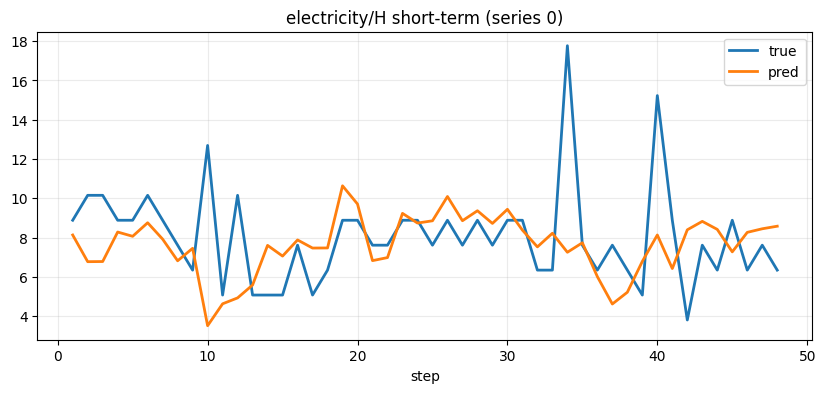

Evaluated: 100, skipped: 0
Mean  MASE: 2.7690  Median: 2.2167  (s-naive: 0.7183)


In [8]:
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)
n_total = len(dataset.hf_dataset)
errors, naive_errors, skipped, plotted = [], [], [], False

for idx in _eval_indices(n_total):
    tr = _train(idx);  va = _val(idx)
    extra = va[len(tr):]
    if len(tr) < CONTEXT_LENGTH or len(extra) < horizon_length:
        skipped.append((idx, "too short")); continue

    obs = tr[np.isfinite(tr)]
    if len(obs) < 2: skipped.append((idx, "all NaN train")); continue
    if NORMALIZATION == "robust_series":
        loc = float(np.median(obs))
        q75, q25 = float(np.percentile(obs,75)), float(np.percentile(obs,25))
        scale = max((q75-q25)/1.349, float(np.std(obs)), 1e-6)
    else:
        loc, scale = 0.0, 1.0

    from src.nested_kriging import _linear_impute
    query_raw = tr[-CONTEXT_LENGTH:]
    query_norm = (_linear_impute(query_raw) - loc) / scale
    pred_norm = forecaster.predict(query_norm)
    pred = pred_norm * scale + loc

    true_h = extra[:horizon_length]
    obs_h = np.isfinite(true_h)
    if not obs_h.any(): skipped.append((idx, "all NaN val-extra")); continue
    _ins_obs = tr[np.isfinite(tr)]
    err = _mase(true_h[obs_h], pred.ravel()[:horizon_length][obs_h], _ins_obs, _sp)
    errors.append(err)
    naive_errors.append(_mase(true_h[obs_h], _seasonal_naive(_ins_obs, horizon_length, _sp)[obs_h], _ins_obs, _sp))

    if (not EVALUATE_ALL_SERIES and idx == SERIES_INDEX) or (EVALUATE_ALL_SERIES and not plotted):
        _plot(true_h, pred.ravel()[:horizon_length],
              title=f"{DATASET_NAME} short-term (series {idx})")
        plotted = True

if errors:
    a = np.asarray(errors, float)
    _n = np.asarray(naive_errors, float)
    print(f"Evaluated: {len(errors)}, skipped: {len(skipped)}")
    print(f"Mean  MASE: {float(np.nanmean(a)):.4f}  Median: {float(np.nanmedian(a)):.4f}  (s-naive: {float(np.nanmean(_n)):.4f})")
else:
    print("No short-term forecasts evaluated."); [print(" ", s) for s in skipped]
short_errors = list(errors) if 'errors' in vars() else []
short_naive_errors = list(naive_errors) if 'naive_errors' in vars() else []


## Re-Fit on Validation Split

In [9]:
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)
print("Collecting validation series …")
val_series = _collect_series("validation", max_s=MAX_SERIES)

print("Pooling validation windows …")
ctx_val, tgt_val, meta_val = pool_windows_from_series_with_missing(
    val_series,
    context_length=CONTEXT_LENGTH,
    horizon_length=horizon_length,
    stride=horizon_length,
    max_windows_per_series=MAX_WINDOWS_PER_SERIES,
    normalization=NORMALIZATION,
    min_observed_fraction=MIN_OBSERVED_FRACTION,
    rng=rng,
)
print(f"  {ctx_val.shape[0]} windows")

print("Fitting Layer 1 on validation …")
ell_field_val = fit_gibbs_lengthscale_field(
    ctx_val, tgt_val,
    block_size_l1=BLOCK_SIZE_L1, sigma_n=SIGMA_N_L1, amplitude=AMPLITUDE_L1,
    log_ell_bounds=(LOG_ELL_LO, LOG_ELL_HI),
    meta_amplitude=META_AMPLITUDE, meta_bandwidth=META_BANDWIDTH, rng=rng,
)
print("Fitting Layer 2 on validation …")
forecaster_val = NestedKrigingForecaster(
    ell_field_val, block_size=BLOCK_SIZE_L2, max_blocks=MAX_BLOCKS_L2,
    sigma_n=SIGMA_N_L2, amplitude=AMPLITUDE_L2, rng=rng,
).fit(ctx_val, tgt_val)
print("Done.")

Pooling validation windows …
  4000 windows
Fitting Layer 1 on validation …
Fitting Layer 2 on validation …
Done.


## Long-Term Evaluation: test window 0

[fig saved → /Users/jonghyeonlee/KMD_TS/experiments/figures/electricity__H_fig01.png]


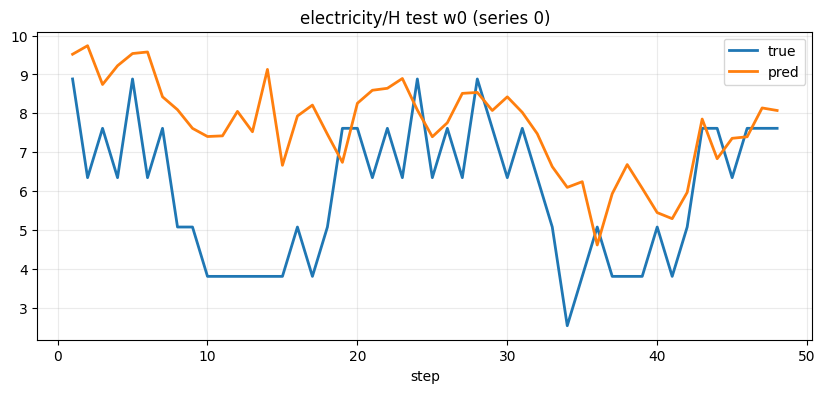

Evaluated: 500, skipped: 0
Mean  MASE: 2.2961  Median: 2.1274  (s-naive: 1.0437)


In [10]:
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)
n_total = len(dataset.hf_dataset)
errors, naive_errors, skipped, plotted = [], [], [], False

from src.nested_kriging import _linear_impute
for idx in _eval_indices(n_total):
    va = _val(idx)
    if len(va) < CONTEXT_LENGTH: skipped.append((idx, "val too short")); continue
    obs = va[np.isfinite(va)]
    if len(obs) < 2: skipped.append((idx, "all NaN val")); continue
    if NORMALIZATION == "robust_series":
        loc = float(np.median(obs))
        q75, q25 = float(np.percentile(obs,75)), float(np.percentile(obs,25))
        scale = max((q75-q25)/1.349, float(np.std(obs)), 1e-6)
    else: loc, scale = 0.0, 1.0

    _ins_obs_long = va[np.isfinite(va)]
    _any_win = False
    for _w in range(dataset.windows if MAX_TEST_WINDOWS is None else min(MAX_TEST_WINDOWS, dataset.windows)):
        try: ctx_e, lbl_e = _test(idx, _w)
        except IndexError: continue
        if len(ctx_e) < CONTEXT_LENGTH or len(lbl_e) < horizon_length: continue
        query_raw = ctx_e[-CONTEXT_LENGTH:]
        query_norm = (_linear_impute(query_raw) - loc) / scale
        pred_norm = forecaster_val.predict(query_norm)
        pred = pred_norm * scale + loc
        true_h = lbl_e[:horizon_length]
        obs_h = np.isfinite(true_h)
        if not obs_h.any(): continue
        errors.append(_mase(true_h[obs_h], pred.ravel()[:horizon_length][obs_h], _ins_obs_long, _sp))
        naive_errors.append(_mase(true_h[obs_h], _seasonal_naive(_ins_obs_long, horizon_length, _sp)[obs_h], _ins_obs_long, _sp))
        _any_win = True
        if (not EVALUATE_ALL_SERIES and idx == SERIES_INDEX) or (EVALUATE_ALL_SERIES and not plotted):
            _plot(true_h, pred.ravel()[:horizon_length],
                  title=f"{DATASET_NAME} test w{_w} (series {idx})")
            plotted = True
    if not _any_win: skipped.append((idx, "no valid test windows")); continue

if errors:
    a = np.asarray(errors, float)
    _n = np.asarray(naive_errors, float)
    print(f"Evaluated: {len(errors)}, skipped: {len(skipped)}")
    print(f"Mean  MASE: {float(np.nanmean(a)):.4f}  Median: {float(np.nanmedian(a)):.4f}  (s-naive: {float(np.nanmean(_n)):.4f})")
else:
    print("No test forecasts evaluated."); [print(" ", s) for s in skipped]

In [11]:
# ── Export model state for cross-dataset nested kriging layer ────────────────
from pathlib import Path
import sys, os; sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), ".."))

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

safe_name = DATASET_NAME.replace("/", "__")
save_path = models_dir / f"{safe_name}.npz"
forecaster.save_state(save_path, dataset_name=DATASET_NAME)
print(f"Saved model state → {save_path}  ({len(forecaster._fitted_blocks)} blocks)")


Saved model state → ../models/electricity__H.npz  (30 blocks)


In [12]:
# ── Save metrics and hyperparameters to JSON ────────────────────────────────
import json as _nk_json
import numpy as _nk_np
_nk_results_dir = REPO_ROOT / "experiments" / "results"
_nk_results_dir.mkdir(parents=True, exist_ok=True)

_nk_hyperparams = {
    "DATASET_NAME":           DATASET_NAME,
    "TERM":                   TERM,
    "CONTEXT_LENGTH":         CONTEXT_LENGTH,
    "HORIZON_LENGTH":         HORIZON_LENGTH,
    "MIN_OBSERVED_FRACTION":  MIN_OBSERVED_FRACTION,
    "BLOCK_SIZE_L1":          BLOCK_SIZE_L1,
    "BLOCK_SIZE_L2":          BLOCK_SIZE_L2,
    "MAX_SERIES":             MAX_SERIES,
    "MAX_BLOCKS_L2":          MAX_BLOCKS_L2,
    "MAX_WINDOWS_PER_SERIES": MAX_WINDOWS_PER_SERIES,
    "SIGMA_N_L1":             SIGMA_N_L1,
    "SIGMA_N_L2":             SIGMA_N_L2,
    "AMPLITUDE_L1":           AMPLITUDE_L1,
    "AMPLITUDE_L2":           AMPLITUDE_L2,
    "LOG_ELL_LO":             LOG_ELL_LO,
    "LOG_ELL_HI":             LOG_ELL_HI,
    "META_AMPLITUDE":         META_AMPLITUDE,
    "META_BANDWIDTH":         META_BANDWIDTH,
    "NORMALIZATION":          NORMALIZATION,
    "SERIES_INDEX":           SERIES_INDEX,
    "EVALUATE_ALL_SERIES":    EVALUATE_ALL_SERIES,
    "EVAL_SERIES_LIMIT":      EVAL_SERIES_LIMIT,
}

_nk_short = [float(e) for e in short_errors] if 'short_errors' in vars() and short_errors else []
_nk_test  = [float(e) for e in errors]       if 'errors'       in vars() and errors       else []

# naive MASE arrays — variable names differ by notebook family
_nk_short_n = [float(e) for e in (
    globals().get('short_naive_errors',        # univariate / missing
    globals().get('all_naive_errors', [])))    # multivariate
]
_nk_test_n  = [float(e) for e in (
    globals().get('test_naive_errors',         # univariate
    globals().get('all_test_naive_errors',     # multivariate
    globals().get('naive_errors', []))))       # missing-data (long eval reuses this)
]

_nk_out = {
    "hyperparameters":    _nk_hyperparams,
    "short_term_MASE":  _nk_short,
    "test_MASE":        _nk_test,
    "metrics": {
        "short_mean_MASE":   float(_nk_np.nanmean(_nk_short))   if _nk_short else None,
        "short_median_MASE": float(_nk_np.nanmedian(_nk_short)) if _nk_short else None,
        "short_n_evaluated":  len(_nk_short),
        "short_mean_s_naive_MASE": float(_nk_np.nanmean(_nk_short_n)) if _nk_short_n else None,
        "test_mean_MASE":    float(_nk_np.nanmean(_nk_test))    if _nk_test  else None,
        "test_median_MASE":  float(_nk_np.nanmedian(_nk_test))  if _nk_test  else None,
        "test_n_evaluated":   len(_nk_test),
        "test_mean_s_naive_MASE":    float(_nk_np.nanmean(_nk_test_n))    if '_nk_test_n' in dir() and _nk_test_n  else None,
    },
}

_nk_safe  = DATASET_NAME.replace("/", "__")
_nk_fpath = _nk_results_dir / f"{_nk_safe}_missing.json"
with open(_nk_fpath, "w") as _nk_f:
    _nk_json.dump(_nk_out, _nk_f, indent=2)
print(f"Results saved → {_nk_fpath}")


Results saved → /Users/jonghyeonlee/KMD_TS/experiments/results/electricity__H_missing.json
